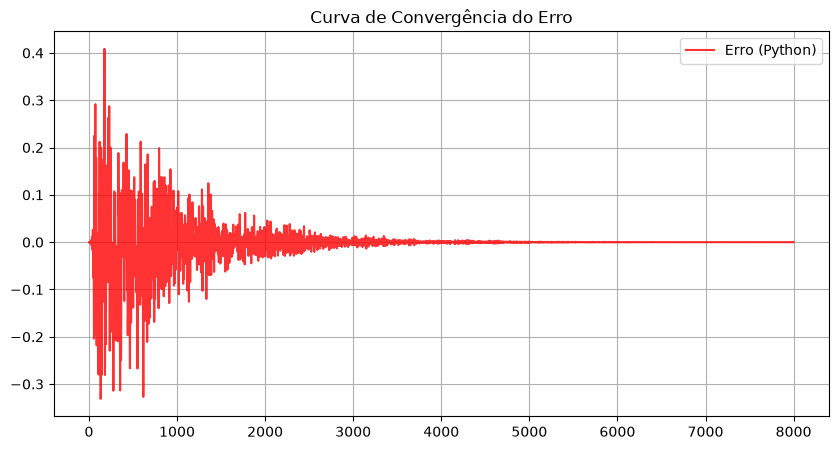

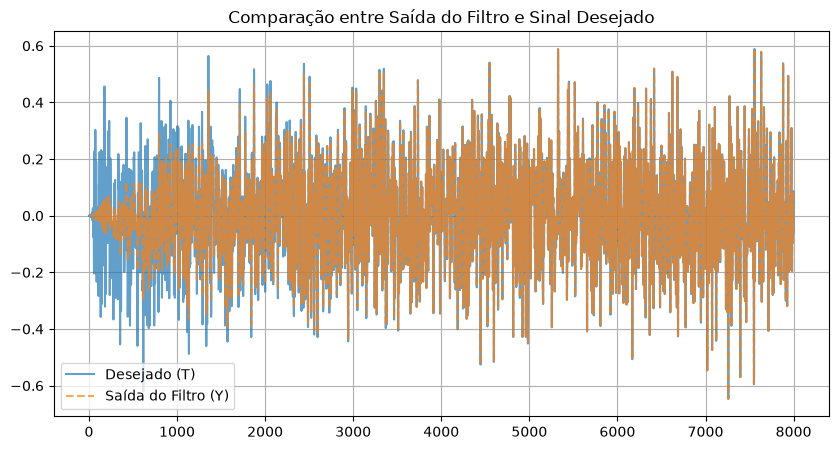

In [4]:
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# 1. FUNÇÕES
# ==========================================
def ler_arquivo_hex(arquivo):
    valores = []
    with open(arquivo, 'r') as f:
        for linha in f:
            linha = linha.strip() 
            if not linha:
                continue
            valor_inteiro = int(linha, 16) 
            if valor_inteiro >= 32768:
                valor_inteiro -= 65536
            valores.append(valor_inteiro)

    # Converte de volta para ponto flutuante (-1.0 a 1.0) usando o divisor Q15
    vetor_x = np.array(valores) / 32768.0 
    return vetor_x

def filtro(w, x):
    N = len(w)
    soma = 0
    for j in range(N):
        soma = soma + w[j] * x[j]
    return soma 

def lms(w, x, e, mu):
    n = len(w) 
    for i in range(n):
        w[i] = w[i] + mu * e * x[i]
    return w

# ==========================================
# 2. CONFIGURAÇÕES (Idênticas ao VHDL)
# ==========================================
# addr_width = 7 gera 2**7 = 128 taps
m = 128  

# Passo mu definido como 328 em Q15 (formato de 16 bits assinado)
mu_vhdl = 328 / 32768.0  

# Lê os arquivos gerados (Entrada e Sinal Desejado)
X = ler_arquivo_hex('ruido_branco.hex')      
T = ler_arquivo_hex('saida_T.hex')   

# Arrays para salvar os resultados
E = np.zeros(len(X))
D_save = np.zeros(len(X))
Y_save = np.zeros(len(X))

W = np.zeros(m)         
janela_x = np.zeros(m)  

# ==========================================
# 3. LOOP DO FILTRO ADAPTATIVO (LMS)
# ==========================================
for i in range(len(X)):
    # Simula o buffer circular do VHDL deslocando o array
    for j in range(m-1, 0, -1):
        janela_x[j] = janela_x[j-1]
    janela_x[0] = X[i]

    # Sinal desejado D (D_in no VHDL)
    D = T[i]

    # Equivalente ao estado FILTRA e cálculo do 'acumulado'
    Y = filtro(W, janela_x)
    
    # Equivalente ao estado CALCULA_ERRO
    e = D - Y
    
    # Salva os estados atuais
    D_save[i] = D
    Y_save[i] = Y
    E[i] = e

    # Equivalente ao estado ATUALIZA_W
    W = lms(W, janela_x, e, mu_vhdl)

# ==========================================
# 4. PLOTS
# ==========================================
plt.figure(figsize=(10, 5))
plt.plot(E, label='Erro (Python)', color='red', alpha=0.8)
plt.grid()
plt.legend()
plt.title("Curva de Convergência do Erro")
plt.show()

plt.figure(figsize=(10, 5))
plt.plot(D_save, label='Desejado (T)', alpha=0.7)
plt.plot(Y_save, label='Saída do Filtro (Y)', alpha=0.7, linestyle='--')
plt.grid()
plt.legend()
plt.title("Comparação entre Saída do Filtro e Sinal Desejado")
plt.show()